# 02 · Machine Learning e Inferencia Bayesiana — PowerShift AI
**Pregunta:** ¿en qué horas del día siguiente va a estar cargando el vehículo eléctrico (EV)?
**Entrada:** `datos_horarios.csv` (salida del notebook 00: vivienda `DE_KN_residential4` de OPSD, 506 días completos, un renglón por hora).
**Salidas:** `resultados_ml.json` (todas las cifras del reporte) y las figuras `fig_ml_*.png`.

**Por qué importa para el orquestador.** El optimizador necesita saber en qué horas es probable que el auto se conecte y cuánta energía va a pedir. Este notebook estima, con la información disponible al cierre del día anterior (como el Mercado del Día en Adelanto), la probabilidad de que el EV esté cargando en cada una de las 24 horas.

**Tipo de problema:** clasificación binaria con clases desbalanceadas (el EV carga en ~9 % de las horas).

Decisiones que se fijaron antes de ver resultados del conjunto de prueba:
1. Objetivo: `y = 1` si la potencia media del EV en la hora es mayor que 0.1 kW (más de 0.1 kWh en la hora).
2. Solo variables conocidas al terminar el día anterior (sin fuga de información).
3. División temporal: un año para entrenar (14 oct 2015 – 13 oct 2016) y el resto para prueba (14 oct 2016 – 5 mar 2017).
4. Hiperparámetros con validación cruzada temporal (ventana creciente) dentro del año de entrenamiento; el umbral de decisión se elige con esas mismas predicciones fuera de muestra.
5. Semilla fija: 42.

In [1]:
import json, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.base import BaseEstimator, ClassifierMixin, clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, KBinsDiscretizer, FunctionTransformer
from sklearn.model_selection import GridSearchCV
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import CategoricalNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss, log_loss,
                             f1_score, precision_score, recall_score, roc_curve, precision_recall_curve)

warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
SEMILLA = 42
UMBRAL_KW = 0.1
CORTE = pd.Timestamp("2016-10-13")          # último día de entrenamiento
RES = {}                                     # aquí se guardan las cifras del reporte

# Paleta (categórica en orden fijo, texto en tonos neutros)
COL = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]
TXT, TXT2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 9.5, "axes.edgecolor": TXT2,
                     "axes.labelcolor": TXT, "xtick.color": TXT2, "ytick.color": TXT2,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "grid.linewidth": 0.6, "axes.titlesize": 10.5,
                     "axes.titleweight": "bold", "legend.frameon": False, "figure.dpi": 110})

## 1. Datos y variable objetivo

In [2]:
h = pd.read_csv("datos_horarios.csv", index_col=0, parse_dates=True)
h.index.name = "ts_local"                      # hora local de Alemania (sin zona)
h["fecha"] = pd.to_datetime(h["fecha"])
print("Renglones (horas):", len(h), "| días:", h["fecha"].nunique(), "|", h["fecha"].min().date(), "->", h["fecha"].max().date())
print("Faltantes por columna:", int(h.isna().sum().sum()))

ev = h["ev"]
dist = {"= 0 kW": (ev == 0).mean(), "0 a 0.1 kW": ((ev > 0) & (ev <= UMBRAL_KW)).mean(), "> 0.1 kW": (ev > UMBRAL_KW).mean()}
print("Distribución de la potencia horaria del EV:", {k: f"{100*v:.1f} %" for k, v in dist.items()})
print("Energía del EV en horas de 0 a 0.1 kW:", f"{100 * ev[(ev > 0) & (ev <= UMBRAL_KW)].sum() / ev.sum():.2f} % del total")
h["y"] = (ev > UMBRAL_KW).astype(int)
for u in [0.05, 0.1, 0.2, 0.5]:
    print(f"  umbral {u:>4} kW -> {100 * (ev > u).mean():.2f} % de horas positivas")
RES["datos"] = dict(horas=len(h), dias=int(h["fecha"].nunique()), pct_cero=100 * dist["= 0 kW"],
                    pct_bajo=100 * dist["0 a 0.1 kW"], pct_pos=100 * dist["> 0.1 kW"])

Renglones (horas): 12144 | días: 506 | 2015-10-14 -> 2017-03-05
Faltantes por columna: 0
Distribución de la potencia horaria del EV: {'= 0 kW': '81.0 %', '0 a 0.1 kW': '9.6 %', '> 0.1 kW': '9.4 %'}
Energía del EV en horas de 0 a 0.1 kW: 0.37 % del total
  umbral 0.05 kW -> 9.73 % de horas positivas
  umbral  0.1 kW -> 9.41 % de horas positivas
  umbral  0.2 kW -> 8.91 % de horas positivas
  umbral  0.5 kW -> 7.53 % de horas positivas


## 2. Variables del día anterior (sin fuga de información)
Para predecir las 24 horas del día *D* solo se usa lo que se sabe al terminar el día *D − 1*:

| Variable | Tipo | Qué mide |
|---|---|---|
| `hora` | categórica (0–23) | hora del día |
| `dia_semana` | categórica (0 = lunes … 6 = domingo) | día de la semana de *D* (se conoce de antemano) |
| `carga_ayer_hora` | binaria | si el EV cargó a esa misma hora el día anterior |
| `carga_semana_hora` | binaria | si cargó a esa hora hace 7 días (mismo día de la semana) |
| `frec_hora_28d` | continua (0–1) | fracción de los últimos 28 días con carga a esa hora |
| `ev_ayer_kwh` | continua (kWh) | energía que cargó el EV el día anterior |
| `horas_carga_7d` | discreta | horas con carga en los 7 días anteriores (si falta un día, se escala el promedio a 7 días) |
| `dias_sin_cargar` | discreta (1–7) | días desde el último día con carga (≥ 0.5 kWh), tope de 7 |

Los 3 días quitados por cambio de horario dejan huecos en el calendario: los rezagos que caen en un hueco quedan vacíos y esos renglones se descartan.

In [3]:
cal = pd.date_range(h["fecha"].min(), h["fecha"].max(), freq="D")
dia = h.groupby("fecha").agg(ev_kwh=("ev", "sum"), horas_carga=("y", "sum")).reindex(cal)
print("Días del calendario:", len(cal), "| días sin datos (cambio de horario):", int(dia["ev_kwh"].isna().sum()))

dia["ev_ayer_kwh"] = dia["ev_kwh"].shift(1)
dia["horas_carga_7d"] = (dia["horas_carga"].shift(1).rolling(7, min_periods=6).mean() * 7).round()  # si falta 1 día se escala
ultima, dias_sin = None, []
for fecha, e in dia["ev_kwh"].items():          # días desde el último día con carga, usando solo días anteriores
    dias_sin.append(np.nan if ultima is None else min((fecha - ultima).days, 7))
    if pd.notna(e) and e >= 0.5:
        ultima = fecha
dia["dias_sin_cargar"] = dias_sin

y_mat = h.pivot_table(index="fecha", columns="hora", values="y").reindex(cal)    # días x 24 horas
rezago = lambda m, nombre: m.stack(future_stack=True).rename(nombre)
lags = pd.concat([rezago(y_mat.shift(1), "carga_ayer_hora"),
                  rezago(y_mat.shift(7), "carga_semana_hora"),
                  rezago(y_mat.shift(1).rolling(28, min_periods=21).mean(), "frec_hora_28d")], axis=1)
lags.index.names = ["fecha", "hora"]

df = (h.reset_index()[["ts_local", "fecha", "hora", "ev", "y"]]
        .merge(lags.reset_index(), on=["fecha", "hora"], how="left")
        .merge(dia[["ev_ayer_kwh", "horas_carga_7d", "dias_sin_cargar"]], left_on="fecha", right_index=True, how="left"))
df["dia_semana"] = df["fecha"].dt.dayofweek
CAT = ["hora", "dia_semana"]
BIN = ["carga_ayer_hora", "carga_semana_hora"]
NUM = ["frec_hora_28d", "ev_ayer_kwh", "horas_carga_7d", "dias_sin_cargar"]
FEAT = CAT + BIN + NUM

antes = df["fecha"].nunique()
df = df.dropna(subset=FEAT).reset_index(drop=True)
df[BIN + ["horas_carga_7d", "dias_sin_cargar"]] = df[BIN + ["horas_carga_7d", "dias_sin_cargar"]].astype(int)
print(f"Días descartados por historia incompleta: {antes - df['fecha'].nunique()} (quedan {df['fecha'].nunique()} días, {len(df)} horas)")

entr, prueba = df[df["fecha"] <= CORTE].reset_index(drop=True), df[df["fecha"] > CORTE].reset_index(drop=True)
Xtr, ytr, Xte, yte = entr[FEAT], entr["y"].to_numpy(), prueba[FEAT], prueba["y"].to_numpy()
print(f"Entrenamiento: {entr['fecha'].min().date()} -> {entr['fecha'].max().date()}, {entr['fecha'].nunique()} días, "
      f"{len(entr)} horas, {100*ytr.mean():.2f} % positivas")
print(f"Prueba:        {prueba['fecha'].min().date()} -> {prueba['fecha'].max().date()}, {prueba['fecha'].nunique()} días, "
      f"{len(prueba)} horas, {100*yte.mean():.2f} % positivas")
RES["division"] = dict(dias_descartados=int(antes - df["fecha"].nunique()), dias=int(df["fecha"].nunique()),
                       dias_entr=int(entr["fecha"].nunique()), horas_entr=len(entr), pos_entr=100 * ytr.mean(),
                       dias_prueba=int(prueba["fecha"].nunique()), horas_prueba=len(prueba), pos_prueba=100 * yte.mean(),
                       inicio_entr=str(entr["fecha"].min().date()), fin_entr=str(entr["fecha"].max().date()),
                       inicio_prueba=str(prueba["fecha"].min().date()), fin_prueba=str(prueba["fecha"].max().date()))

Días del calendario: 509 | días sin datos (cambio de horario): 3
Días descartados por historia incompleta: 25 (quedan 481 días, 11544 horas)
Entrenamiento: 2015-11-05 -> 2016-10-13, 341 días, 8184 horas, 8.44 % positivas
Prueba:        2016-10-14 -> 2017-03-05, 140 días, 3360 horas, 11.93 % positivas


## 3. Análisis exploratorio (solo con el año de entrenamiento)

                  mean   std  min    50%    max
frec_hora_28d     0.09  0.12  0.0   0.04   0.56
ev_ayer_kwh       2.64  3.28  0.0   0.81  14.36
horas_carga_7d   14.27  6.05  0.0  14.00  33.00
dias_sin_cargar   2.04  1.46  1.0   1.00   7.00

Horas con más carga: {13: 30.5, 12: 27.0, 14: 27.0, 11: 20.5, 15: 20.5}
P(carga) por día de la semana (%): {0: 4.3, 1: 6.3, 2: 8.3, 3: 7.0, 4: 8.2, 5: 12.2, 6: 12.9}
Energía del EV entre 10:00 y 17:00 h: 83.0 %
Energía del EV entre 18:00 y 08:00 h: 7.2 %
P(carga | carga_ayer_hora=1) = 0.230   P(carga | carga_ayer_hora=0) = 0.071
P(carga | carga_semana_hora=1) = 0.206   P(carga | carga_semana_hora=0) = 0.073

Correlación de Spearman con y:
 frec_hora_28d        0.329
ev_ayer_kwh          0.003
horas_carga_7d       0.005
dias_sin_cargar     -0.010
carga_ayer_hora      0.159
carga_semana_hora    0.133


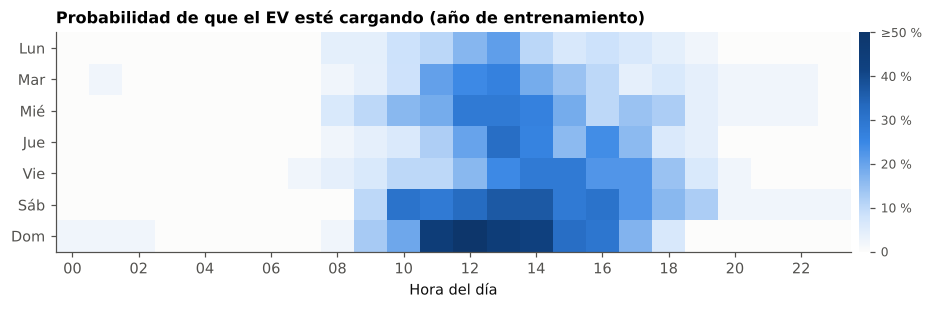

In [4]:
print(entr[NUM].describe().round(2).T[["mean", "std", "min", "50%", "max"]])
p_hora = entr.groupby("hora")["y"].mean()
p_dia = entr.groupby("dia_semana")["y"].mean()
print("\nHoras con más carga:", (100 * p_hora.sort_values(ascending=False).head(5)).round(1).to_dict())
print("P(carga) por día de la semana (%):", (100 * p_dia).round(1).to_dict())
print("Energía del EV entre 10:00 y 17:00 h:", f"{100 * h.loc[h.index.hour.isin(range(10, 17)), 'ev'].sum() / h['ev'].sum():.1f} %")
print("Energía del EV entre 18:00 y 08:00 h:", f"{100 * h.loc[~h.index.hour.isin(range(8, 18)), 'ev'].sum() / h['ev'].sum():.1f} %")
for v in BIN:
    print(f"P(carga | {v}=1) = {entr.loc[entr[v]==1,'y'].mean():.3f}   P(carga | {v}=0) = {entr.loc[entr[v]==0,'y'].mean():.3f}")
corr = entr[NUM + BIN + ["y"]].corr(method="spearman")["y"].drop("y").round(3)
print("\nCorrelación de Spearman con y:\n", corr.to_string())
RES["eda"] = dict(p_hora_max=float(p_hora.max()), hora_max=int(p_hora.idxmax()),
                  p_dia={int(k): float(v) for k, v in p_dia.items()},
                  ev_10_17=float(h.loc[h.index.hour.isin(range(10, 17)), 'ev'].sum() / h['ev'].sum()),
                  ev_noche=float(h.loc[~h.index.hour.isin(range(8, 18)), 'ev'].sum() / h['ev'].sum()),
                  p_dado={v: [float(entr.loc[entr[v]==0,'y'].mean()), float(entr.loc[entr[v]==1,'y'].mean())] for v in BIN},
                  spearman=corr.to_dict())

# Figura 1: probabilidad de carga por hora y día (mapa de calor, escala secuencial azul)
from matplotlib.colors import LinearSegmentedColormap
azul = LinearSegmentedColormap.from_list("azul", ["#fcfcfb", "#cde2fb", "#86b6ef", "#3987e5", "#256abf", "#104281", "#0d366b"])
mapa = entr.pivot_table(index="dia_semana", columns="hora", values="y", aggfunc="mean")
fig, ax = plt.subplots(figsize=(8.6, 2.9))
im = ax.imshow(mapa.values, aspect="auto", cmap=azul, vmin=0, vmax=0.5)
ax.set_yticks(range(7), ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"])
ax.set_xticks(range(0, 24, 2), [f"{x:02d}" for x in range(0, 24, 2)])
ax.set_xlabel("Hora del día"); ax.grid(False)
ax.set_title("Probabilidad de que el EV esté cargando (año de entrenamiento)", loc="left")
cb = fig.colorbar(im, ax=ax, fraction=0.025, pad=0.01); cb.outline.set_visible(False); cb.ax.tick_params(labelsize=8)
cb.set_ticks([0, 0.1, 0.2, 0.3, 0.4, 0.5]); cb.set_ticklabels(["0", "10 %", "20 %", "30 %", "40 %", "≥50 %"])
fig.tight_layout(); fig.savefig("fig_ml_eda_hora_dia.png", dpi=200)

## 4. Modelos
Seis clasificadores, cada uno con su propio preprocesamiento:

| Modelo | Preprocesamiento | Hiperparámetros que se ajustan |
|---|---|---|
| Bayes por hora y día (Beta-Binomial) | ninguno: cuenta cargas por (hora, día) | fuerza del *prior* |
| Regresión Logística | *one-hot* de hora y día; estandarización de las continuas | C (inverso de la regularización L2) |
| Naive Bayes categórico | continuas discretizadas en cuantiles | número de intervalos, α (suavizado de Laplace) |
| Árbol de Decisión | ninguno | profundidad máxima, mínimo de muestras por hoja |
| Random Forest | ninguno | profundidad máxima, mínimo de muestras por hoja |
| KNN | hora y día como seno y coseno; estandarización | k, pesos |

El modelo Beta-Binomial es nuestro: para cada combinación (hora, día de la semana) la probabilidad de carga θ tiene un *prior* Beta centrado en la tasa global, y se predice con la media *a posteriori*.

In [5]:
class BayesHoraDia(ClassifierMixin, BaseEstimator):
    # Beta-Binomial por celda (hora, dia_semana); prior Beta(s*p0, s*(1-p0)), predicción = media a posteriori
    def __init__(self, fuerza_prior=10.0):
        self.fuerza_prior = fuerza_prior
    def fit(self, X, y):
        y = np.asarray(y); self.classes_ = np.array([0, 1]); self.p0_ = y.mean()
        g = pd.DataFrame({"h": X["hora"].to_numpy(), "d": X["dia_semana"].to_numpy(), "y": y}).groupby(["h", "d"])["y"]
        k, n = g.sum(), g.count()
        self.a_ = self.fuerza_prior * self.p0_ + k
        self.b_ = self.fuerza_prior * (1 - self.p0_) + n - k
        return self
    def predict_proba(self, X):
        idx = pd.MultiIndex.from_arrays([X["hora"].to_numpy(), X["dia_semana"].to_numpy()])
        p = (self.a_ / (self.a_ + self.b_)).reindex(idx).fillna(self.p0_).to_numpy()
        return np.c_[1 - p, p]
    def predict(self, X):
        return (self.predict_proba(X)[:, 1] >= 0.5).astype(int)

def a_ciclico(X):                       # hora y día de la semana como puntos en un círculo
    X = np.asarray(X, dtype=float)
    return np.c_[np.sin(2*np.pi*X[:, 0]/24), np.cos(2*np.pi*X[:, 0]/24), np.sin(2*np.pi*X[:, 1]/7), np.cos(2*np.pi*X[:, 1]/7)]
ciclico = FunctionTransformer(a_ciclico)
a_entero = FunctionTransformer(lambda X: np.asarray(X).astype(int))

modelos = {
    "Bayes por hora y día": (BayesHoraDia(), {"fuerza_prior": [0.05, 0.1, 0.25, 0.5, 1, 2, 5, 10, 20, 50, 100]}),
    "Regresión Logística": (Pipeline([
        ("pre", ColumnTransformer([("cat", OneHotEncoder(handle_unknown="ignore"), CAT),
                                   ("bin", "passthrough", BIN), ("num", StandardScaler(), NUM)])),
        ("clf", LogisticRegression(max_iter=5000))]), {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Naive Bayes": (Pipeline([
        ("pre", ColumnTransformer([("cat", "passthrough", CAT + BIN),
                                   ("num", KBinsDiscretizer(n_bins=4, encode="ordinal", strategy="quantile"), NUM)])),
        ("int", a_entero), ("clf", CategoricalNB(min_categories=[24, 7, 2, 2, 6, 6, 6, 6]))]),
        {"pre__num__n_bins": [2, 3, 4, 5, 6], "clf__alpha": [0.0001, 0.001, 0.01, 0.1, 0.5, 1, 2]}),
    "Árbol de Decisión": (DecisionTreeClassifier(random_state=SEMILLA),
                          {"max_depth": [3, 4, 5, 6, 8], "min_samples_leaf": [20, 50, 100]}),
    "Random Forest": (RandomForestClassifier(n_estimators=300, max_features="sqrt", random_state=SEMILLA, n_jobs=-1),
                      {"max_depth": [2, 3, 4, 6, 10, None], "min_samples_leaf": [5, 10, 20, 50, 100]}),
    "KNN": (Pipeline([
        ("pre", ColumnTransformer([("cic", ciclico, CAT), ("bin", "passthrough", BIN), ("num", StandardScaler(), NUM)])),
        ("esc", StandardScaler()), ("clf", KNeighborsClassifier())]),
        {"clf__n_neighbors": [51, 101, 201, 401, 801], "clf__weights": ["uniform", "distance"]}),
}

# Validación cruzada temporal: el año de entrenamiento se parte en 5 bloques de días consecutivos;
# el pliegue k entrena con los bloques anteriores y valida con el bloque k (ventana creciente).
dias_tr = np.sort(entr["fecha"].unique())
bloques = np.array_split(dias_tr, 5)
pliegues = [(np.flatnonzero(entr["fecha"].isin(np.concatenate(bloques[:k]))),
             np.flatnonzero(entr["fecha"].isin(bloques[k]))) for k in range(1, 5)]
for k, (a, b) in enumerate(pliegues, 1):
    print(f"Pliegue {k}: entrena {len(a)} horas, valida {len(b)} horas ({pd.Timestamp(bloques[k][0]).date()} -> {pd.Timestamp(bloques[k][-1]).date()})")

Pliegue 1: entrena 1656 horas, valida 1632 horas (2016-01-13 -> 2016-03-20)
Pliegue 2: entrena 3288 horas, valida 1632 horas (2016-03-21 -> 2016-05-30)
Pliegue 3: entrena 4920 horas, valida 1632 horas (2016-05-31 -> 2016-08-06)
Pliegue 4: entrena 6552 horas, valida 1632 horas (2016-08-07 -> 2016-10-13)


In [6]:
ajustados, filas = {}, []
for nombre, (est, grid) in modelos.items():
    gs = GridSearchCV(est, grid, scoring="average_precision", cv=pliegues, n_jobs=-1, refit=False)
    gs.fit(Xtr, ytr)
    mejor = clone(est).set_params(**gs.best_params_)
    # predicciones fuera de muestra de los 4 pliegues para elegir el umbral que maximiza F1
    oof_p, oof_y = [], []
    for a, b in pliegues:
        m = clone(mejor).fit(Xtr.iloc[a], ytr[a]); oof_p.append(m.predict_proba(Xtr.iloc[b])[:, 1]); oof_y.append(ytr[b])
    oof_p, oof_y = np.concatenate(oof_p), np.concatenate(oof_y)
    umbrales = np.round(np.arange(0.05, 0.951, 0.01), 2)
    f1s = [f1_score(oof_y, oof_p >= u, zero_division=0) for u in umbrales]
    u_opt = float(umbrales[int(np.argmax(f1s))])
    t0 = time.perf_counter(); mejor.fit(Xtr, ytr); t_fit = time.perf_counter() - t0
    t0 = time.perf_counter(); p = mejor.predict_proba(Xte)[:, 1]; t_pred = time.perf_counter() - t0
    ajustados[nombre] = dict(modelo=mejor, p=p, umbral=u_opt)
    filas.append(dict(modelo=nombre, params=gs.best_params_, ap_cv=gs.best_score_, umbral=u_opt,
                      auc=roc_auc_score(yte, p), ap=average_precision_score(yte, p), brier=brier_score_loss(yte, p),
                      logloss=log_loss(yte, np.clip(p, 1e-6, 1 - 1e-6)), f1=f1_score(yte, p >= u_opt),
                      precision=precision_score(yte, p >= u_opt, zero_division=0), recall=recall_score(yte, p >= u_opt),
                      t_fit=t_fit, t_pred=t_pred))
    rango = (gs.cv_results_["mean_test_score"].min(), gs.cv_results_["mean_test_score"].max())
    filas[-1]["ap_cv_min"], filas[-1]["ap_cv_max"] = rango
    print(f"{nombre:22s} mejores {gs.best_params_} | AP en validación {gs.best_score_:.3f} "
          f"(malla completa: {rango[0]:.3f} a {rango[1]:.3f}) | umbral {u_opt:.2f}")

tabla = pd.DataFrame(filas).set_index("modelo")
params_finales = tabla.pop("params").to_dict()
brier_ref = brier_score_loss(yte, np.full(len(yte), ytr.mean()))          # pronóstico constante = tasa de entrenamiento
tabla["bss"] = 1 - tabla["brier"] / brier_ref
print(f"\nReferencia: tasa base de prueba {yte.mean():.3f} (AP de un modelo al azar), Brier de la tasa constante {brier_ref:.4f}")
pd.set_option("display.width", 200)
print(tabla[["ap_cv", "auc", "ap", "brier", "bss", "logloss", "umbral", "f1", "precision", "recall", "t_fit", "t_pred"]].round(3))

Bayes por hora y día   mejores {'fuerza_prior': 0.05} | AP en validación 0.255 (malla completa: 0.254 a 0.255) | umbral 0.13


Regresión Logística    mejores {'clf__C': 10} | AP en validación 0.281 (malla completa: 0.232 a 0.281) | umbral 0.13


Naive Bayes            mejores {'clf__alpha': 0.0001, 'pre__num__n_bins': 2} | AP en validación 0.254 (malla completa: 0.247 a 0.254) | umbral 0.21


Árbol de Decisión      mejores {'max_depth': 4, 'min_samples_leaf': 50} | AP en validación 0.238 (malla completa: 0.203 a 0.238) | umbral 0.16


Random Forest          mejores {'max_depth': 4, 'min_samples_leaf': 10} | AP en validación 0.275 (malla completa: 0.246 a 0.275) | umbral 0.19


KNN                    mejores {'clf__n_neighbors': 401, 'clf__weights': 'distance'} | AP en validación 0.240 (malla completa: 0.228 a 0.240) | umbral 0.12

Referencia: tasa base de prueba 0.119 (AP de un modelo al azar), Brier de la tasa constante 0.1063
                      ap_cv    auc     ap  brier    bss  logloss  umbral     f1  precision  recall  t_fit  t_pred
modelo                                                                                                           
Bayes por hora y día  0.255  0.860  0.361  0.088  0.175    0.276    0.13  0.465      0.337   0.746  0.002   0.001
Regresión Logística   0.281  0.852  0.377  0.087  0.180    0.277    0.13  0.450      0.319   0.763  0.035   0.007
Naive Bayes           0.254  0.848  0.361  0.102  0.039    0.323    0.21  0.459      0.324   0.783  0.012   0.005
Árbol de Decisión     0.238  0.838  0.330  0.089  0.161    0.281    0.16  0.423      0.320   0.626  0.007   0.001
Random Forest         0.275  0.852  0.374  0.089  0.163    0

In [7]:
# Robustez: intervalos de confianza al 95 % por bootstrap de días completos del periodo de prueba (1,000 remuestreos)
rng = np.random.default_rng(SEMILLA)
dias_te = prueba["fecha"].to_numpy()
u_dias = np.unique(dias_te)
pos_por_dia = {d: np.flatnonzero(dias_te == d) for d in u_dias}
B = 1000
boot = {n: {"auc": [], "ap": []} for n in ajustados}
for _ in range(B):
    idx = np.concatenate([pos_por_dia[d] for d in rng.choice(u_dias, size=len(u_dias), replace=True)])
    yb = yte[idx]
    for n, a in ajustados.items():
        boot[n]["auc"].append(roc_auc_score(yb, a["p"][idx])); boot[n]["ap"].append(average_precision_score(yb, a["p"][idx]))
for n in ajustados:
    for m in ["auc", "ap"]:
        lo, hi = np.percentile(boot[n][m], [2.5, 97.5]); tabla.loc[n, f"{m}_lo"], tabla.loc[n, f"{m}_hi"] = lo, hi
print(tabla[["auc", "auc_lo", "auc_hi", "ap", "ap_lo", "ap_hi"]].round(3))

                        auc  auc_lo  auc_hi     ap  ap_lo  ap_hi
modelo                                                          
Bayes por hora y día  0.860   0.837   0.882  0.361  0.292  0.440
Regresión Logística   0.852   0.824   0.877  0.377  0.303  0.468
Naive Bayes           0.848   0.821   0.874  0.361  0.296  0.446
Árbol de Decisión     0.838   0.815   0.861  0.330  0.269  0.397
Random Forest         0.852   0.824   0.876  0.374  0.302  0.464
KNN                   0.857   0.832   0.879  0.383  0.320  0.460


## 5. Selección del modelo final
Se elige con la validación cruzada del año de entrenamiento (AP), no con la prueba, y se pesan la calidad de las probabilidades (Brier), la interpretabilidad y el costo de cómputo en la Raspberry Pi.

In [8]:
orden = tabla.sort_values("ap_cv", ascending=False)
tabla["p_media"] = [ajustados[n]["p"].mean() for n in tabla.index]
orden = tabla.sort_values("ap_cv", ascending=False)
print(orden[["ap_cv", "ap", "auc", "brier", "p_media", "t_fit", "t_pred"]].round(4))
print(f"Tasa real de carga en prueba: {yte.mean():.4f} (entrenamiento: {ytr.mean():.4f})")
FINAL = orden.index[0]
print("\nModelo con mejor AP en validación cruzada:", FINAL)

# Interpretación de la Regresión Logística: razones de momios (odds ratios)
lr = ajustados["Regresión Logística"]["modelo"]
nombres = lr.named_steps["pre"].get_feature_names_out()
coef = pd.Series(lr.named_steps["clf"].coef_[0], index=nombres)
odds = np.exp(coef)
print("\nRazones de momios de las variables no horarias (continuas: por 1 desviación estándar):")
print(odds[[c for c in nombres if c.startswith(("bin__", "num__", "cat__dia"))]].round(3).to_string())
print("Intercepto:", round(float(lr.named_steps["clf"].intercept_[0]), 3))
hora_odds = odds[[c for c in nombres if c.startswith("cat__hora")]]
print("Hora con mayor razón de momios:", hora_odds.idxmax(), round(float(hora_odds.max()), 2), "| menor:", hora_odds.idxmin(), round(float(hora_odds.min()), 3))

# Importancia por permutación (caída de AP en prueba) del modelo final
pi = permutation_importance(ajustados[FINAL]["modelo"], Xte, yte, scoring="average_precision", n_repeats=10, random_state=SEMILLA, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=FEAT).sort_values(ascending=False)
print(f"\nImportancia por permutación ({FINAL}), caída de AP:\n", imp.round(4).to_string())
RES["logistica"] = dict(odds={k: float(v) for k, v in odds.items() if not k.startswith("cat__hora")},
                        intercepto=float(lr.named_steps["clf"].intercept_[0]),
                        hora_max=[hora_odds.idxmax(), float(hora_odds.max())], hora_min=[hora_odds.idxmin(), float(hora_odds.min())])
RES["importancia_final"] = imp.to_dict()

                       ap_cv      ap     auc   brier  p_media   t_fit  t_pred
modelo                                                                       
Regresión Logística   0.2811  0.3772  0.8519  0.0872   0.0891  0.0351  0.0068
Random Forest         0.2753  0.3736  0.8520  0.0889   0.0886  0.6735  0.0862
Bayes por hora y día  0.2551  0.3607  0.8602  0.0877   0.0849  0.0024  0.0013
Naive Bayes           0.2539  0.3611  0.8481  0.1022   0.1696  0.0120  0.0054
KNN                   0.2397  0.3825  0.8572  0.0879   0.0867  0.0168  0.5563
Árbol de Decisión     0.2375  0.3297  0.8384  0.0892   0.0892  0.0072  0.0012
Tasa real de carga en prueba: 0.1193 (entrenamiento: 0.0844)

Modelo con mejor AP en validación cruzada: Regresión Logística

Razones de momios de las variables no horarias (continuas: por 1 desviación estándar):
cat__dia_semana_0         0.304
cat__dia_semana_1         0.475
cat__dia_semana_2         0.693
cat__dia_semana_3         0.554
cat__dia_semana_4         0.670
cat


Importancia por permutación (Regresión Logística), caída de AP:
 hora                 0.2315
ev_ayer_kwh          0.0236
dia_semana           0.0208
frec_hora_28d        0.0060
carga_ayer_hora      0.0001
horas_carga_7d      -0.0004
dias_sin_cargar     -0.0042
carga_semana_hora   -0.0121


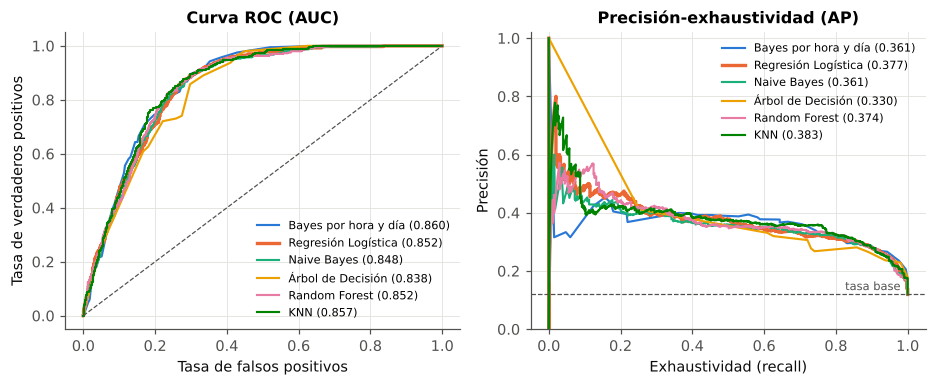

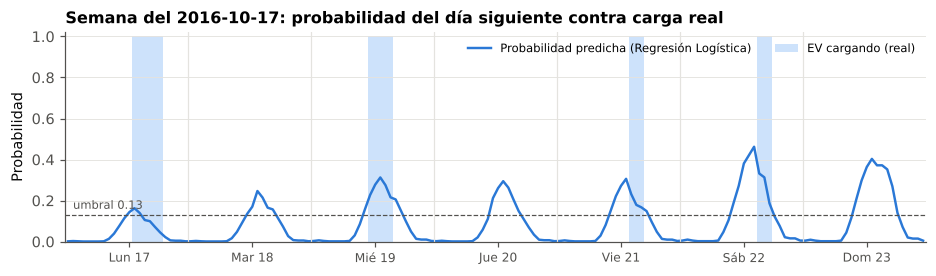

In [9]:
# Figura 2: curvas ROC y precisión-exhaustividad en el periodo de prueba
fig, (a1, a2) = plt.subplots(1, 2, figsize=(8.6, 3.6))
for (n, a), c in zip(ajustados.items(), COL):
    fpr, tpr, _ = roc_curve(yte, a["p"]); pr, rc, _ = precision_recall_curve(yte, a["p"])
    lw = 2.2 if n == FINAL else 1.4
    a1.plot(fpr, tpr, color=c, lw=lw, label=f"{n} ({tabla.loc[n,'auc']:.3f})")
    a2.plot(rc, pr, color=c, lw=lw, label=f"{n} ({tabla.loc[n,'ap']:.3f})")
a1.plot([0, 1], [0, 1], ls="--", color=TXT2, lw=0.8); a2.axhline(yte.mean(), ls="--", color=TXT2, lw=0.8)
a1.set(xlabel="Tasa de falsos positivos", ylabel="Tasa de verdaderos positivos", title="Curva ROC (AUC)")
a2.set(xlabel="Exhaustividad (recall)", ylabel="Precisión", title="Precisión-exhaustividad (AP)", ylim=(0, 1.02))
a1.legend(fontsize=7.4, loc="lower right"); a2.legend(fontsize=7.4, loc="upper right")
a2.annotate("tasa base", (0.98, yte.mean() + 0.015), ha="right", fontsize=7.5, color=TXT2)
fig.tight_layout(); fig.savefig("fig_ml_roc_pr.png", dpi=200)

# Figura 3: una semana del periodo de prueba (la primera semana completa, lunes a domingo)
lunes = prueba.loc[prueba["fecha"].dt.dayofweek == 0, "fecha"].min()
sem = prueba[(prueba["fecha"] >= lunes) & (prueba["fecha"] < lunes + pd.Timedelta(days=7))].copy()
sem["p"] = ajustados[FINAL]["p"][sem.index]
fig, ax = plt.subplots(figsize=(8.6, 2.6))
x = np.arange(len(sem))
ax.bar(x[sem["y"] == 1], 1, width=1.0, color="#cde2fb", label="EV cargando (real)")
ax.plot(x, sem["p"], color=COL[0], lw=1.6, label=f"Probabilidad predicha ({FINAL})")
ax.axhline(ajustados[FINAL]["umbral"], ls="--", color=TXT2, lw=0.8)
ax.annotate(f"umbral {ajustados[FINAL]['umbral']:.2f}", (1, ajustados[FINAL]["umbral"] + 0.03), ha="left", fontsize=7.5, color=TXT2)
ticks = np.arange(0, len(sem), 24)
DIAS = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
ax.set_xticks(ticks + 12, [f"{DIAS[d.dayofweek]} {d.day}" for d in sem["fecha"].iloc[ticks]], fontsize=8)
for t in ticks[1:]:
    ax.axvline(t - 0.5, color=GRID, lw=0.8)
ax.set(ylim=(0, 1.02), xlim=(-0.5, len(sem) - 0.5), ylabel="Probabilidad")
ax.set_title(f"Semana del {lunes.date()}: probabilidad del día siguiente contra carga real", loc="left")
ax.grid(axis="x", visible=False); ax.legend(fontsize=7.6, loc="upper right", ncol=2)
fig.tight_layout(); fig.savefig("fig_ml_semana.png", dpi=200)
RES["semana"] = str(lunes.date())

## 6. Inferencia bayesiana: probabilidad de carga por hora
Modelo conjugado Beta-Binomial con *prior* uniforme Beta(1, 1): si en una hora se observaron *k* cargas en *n* días, la distribución *a posteriori* de θ es Beta(1 + k, 1 + n − k). Se separan días laborables y fines de semana.

                k    n   a    b  media     lo     hi
tipo                                                
Fin de semana  39   96  40   58  0.408  0.313  0.507
Laborable      65  245  66  181  0.267  0.214  0.324
P(θ_fin de semana > θ_laborable | datos) a las 13 h = 0.9941
Diferencia media: 0.141, IC 95 %: [0.030, 0.253]

Hora pico por tipo de día:
          tipo  hora  media    lo    hi
Fin de semana    12  0.418 0.323 0.517
    Laborable    13  0.267 0.214 0.324

Bayes por hora y día: fuerza del prior elegida = 0.05, p0 = 0.0844


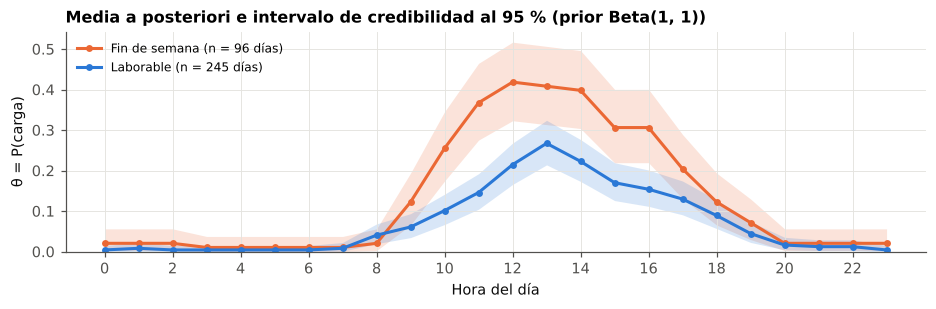

In [10]:
entr["tipo"] = np.where(entr["dia_semana"] >= 5, "Fin de semana", "Laborable")
post = entr.groupby(["tipo", "hora"])["y"].agg(k="sum", n="count").reset_index()
post["a"], post["b"] = 1 + post["k"], 1 + post["n"] - post["k"]
post["media"] = post["a"] / (post["a"] + post["b"])
post["lo"], post["hi"] = stats.beta.ppf(0.025, post["a"], post["b"]), stats.beta.ppf(0.975, post["a"], post["b"])

fig, ax = plt.subplots(figsize=(8.6, 2.9))
for (t, g), c in zip(post.groupby("tipo"), [COL[1], COL[0]]):
    ax.fill_between(g["hora"], g["lo"], g["hi"], color=c, alpha=0.18, lw=0)
    ax.plot(g["hora"], g["media"], color=c, lw=2, marker="o", ms=3.5, label=f"{t} (n = {int(g['n'].iloc[0])} días)")
ax.set(xlabel="Hora del día", ylabel="θ = P(carga)", xticks=range(0, 24, 2), ylim=(0, None))
ax.set_title("Media a posteriori e intervalo de credibilidad al 95 % (prior Beta(1, 1))", loc="left")
ax.legend(fontsize=8, loc="upper left"); fig.tight_layout(); fig.savefig("fig_ml_beta_hora.png", dpi=200)

# ¿Es más probable cargar a las 13 h en fin de semana que en día laborable? Monte Carlo sobre las posteriores
r13 = post[post["hora"] == 13].set_index("tipo")
rng2 = np.random.default_rng(SEMILLA)
th_f = rng2.beta(r13.loc["Fin de semana", "a"], r13.loc["Fin de semana", "b"], 200_000)
th_l = rng2.beta(r13.loc["Laborable", "a"], r13.loc["Laborable", "b"], 200_000)
p_mayor = float((th_f > th_l).mean())
print(r13[["k", "n", "a", "b", "media", "lo", "hi"]].round(3))
print(f"P(θ_fin de semana > θ_laborable | datos) a las 13 h = {p_mayor:.4f}")
print(f"Diferencia media: {np.mean(th_f - th_l):.3f}, IC 95 %: [{np.percentile(th_f - th_l, 2.5):.3f}, {np.percentile(th_f - th_l, 97.5):.3f}]")
pico = post.loc[post.groupby("tipo")["media"].idxmax(), ["tipo", "hora", "media", "lo", "hi"]]
print("\nHora pico por tipo de día:\n", pico.round(3).to_string(index=False))
bh = ajustados["Bayes por hora y día"]["modelo"]
print(f"\nBayes por hora y día: fuerza del prior elegida = {bh.fuerza_prior}, p0 = {bh.p0_:.4f}")
RES["bayes"] = dict(h13={t: dict(k=int(r13.loc[t, "k"]), n=int(r13.loc[t, "n"]), media=float(r13.loc[t, "media"]),
                                 lo=float(r13.loc[t, "lo"]), hi=float(r13.loc[t, "hi"])) for t in r13.index},
                    p_mayor=p_mayor, dif_media=float(np.mean(th_f - th_l)),
                    dif_ic=[float(np.percentile(th_f - th_l, 2.5)), float(np.percentile(th_f - th_l, 97.5))],
                    pico={r.tipo: dict(hora=int(r.hora), media=float(r.media), lo=float(r.lo), hi=float(r.hi)) for r in pico.itertuples()},
                    fuerza_prior=float(bh.fuerza_prior), p0=float(bh.p0_))

## 7. Guardar resultados

In [11]:
RES["final"] = FINAL
RES["params"] = {n: {k: (v if not isinstance(v, (np.floating, np.integer)) else v.item()) for k, v in d.items()} for n, d in params_finales.items()}
RES["brier_ref"] = float(brier_ref)
RES["tabla"] = {n: {k: (v if isinstance(v, dict) else float(v)) for k, v in fila.items()} for n, fila in tabla.to_dict("index").items()}
json.dump(RES, open("resultados_ml.json", "w"), indent=1, ensure_ascii=False, default=str)
print("Guardado resultados_ml.json y figuras fig_ml_*.png")

Guardado resultados_ml.json y figuras fig_ml_*.png
